<div dir="rtl">

# Baseline متنی Digikala: TF-IDF + Logistic Regression

در این نوت‌بوک دو baseline ساده برای پیش‌بینی وضعیت پیشنهاد و بازه امتیاز می‌سازیم. ورودی مدل فقط متن نرمال‌شدهٔ body است. فایل‌های split آمادهٔ preprocess استفاده می‌شوند تا جداسازی گروهی بر اساس محصول حفظ شود.

**پیش‌نیازها:** pandas، numpy، matplotlib، seaborn و scikit-learn.

داده‌ها بزرگ‌اند؛ اجرای پیش‌فرض با نمونه‌گیری ثابت انجام می‌شود. برای استفاده از همهٔ داده‌ها، LIMITS را None کنید؛ این کار RAM و زمان بیشتری می‌خواهد.

In [9]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

SEED = 2026
TEXT_COLUMN = 'body'
TARGETS = {
    'recommendation_status': ['recommended', 'not_recommended', 'no_idea'],
    'rating_band': ['low', 'medium', 'high'],
}

# مسیرها از ریشه پروژه و از پوشه src پشتیبانی می‌شوند.
DATA_CANDIDATES = [
    Path('data/clean_data/split_body_cleaned'),
    Path('../data/clean_data/split_body_cleaned'),
]
DATA_DIR = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError('پوشه split_body_cleaned پیدا نشد؛ مسیر پروژه را بررسی کنید.')

SPLIT_FILES = {
    'train': DATA_DIR / 'train_supervised.csv',
    'validation': DATA_DIR / 'validation.csv',
    'test': DATA_DIR / 'test.csv',
}

# برای اجرای اولیه؛ None یعنی کل split.
LIMITS = {'train': None, 'validation': None, 'test': None}
print(f'داده‌ها: {DATA_DIR.resolve()}')

داده‌ها: E:\MLprojects\Transformer-Project\data\clean_data\split_body_cleaned


<div dir="rtl">

## 1. بارگذاری داده‌ها

فقط سه ستون لازم خوانده می‌شود: متن، وضعیت پیشنهاد و rating_band. بارگذاری به صورت تکه‌ای انجام می‌شود تا کل فایل چندمیلیونی یک‌باره وارد حافظه نشود. از هر تکه سهم متناسبی نمونه‌گیری می‌کنیم و در پایان، سقف نمونه را اعمال می‌کنیم.

In [10]:
def load_split(path, limit, expected_rows=None, chunksize=100_000):
    """بارگذاری تکه‌ای با نمونه‌گیری ثابت و کم‌مصرف‌تر از نظر حافظه."""
    columns = [TEXT_COLUMN, *TARGETS.keys()]
    chunks = []
    chunk_number = 0

    if limit is not None and expected_rows:
        sample_fraction = min(limit / expected_rows, 1.0)
    else:
        sample_fraction = 1.0

    for chunk in pd.read_csv(
        path,
        usecols=columns,
        encoding='utf-8',
        chunksize=chunksize,
    ):
        chunk[TEXT_COLUMN] = chunk[TEXT_COLUMN].fillna('').astype(str)
        chunk = chunk.loc[chunk[TEXT_COLUMN].str.strip().ne('')].copy()
        if chunk.empty:
            continue

        if limit is not None and sample_fraction < 1.0:
            chunk = chunk.sample(
                frac=sample_fraction,
                random_state=SEED + chunk_number,
            )
        if not chunk.empty:
            chunks.append(chunk)
        chunk_number += 1

    if not chunks:
        raise ValueError(f'هیچ متن معتبری در {path} پیدا نشد.')

    frame = pd.concat(chunks, ignore_index=True)
    if limit is not None and len(frame) > limit:
        frame = frame.sample(n=limit, random_state=SEED).reset_index(drop=True)
    return frame.reset_index(drop=True)

with (DATA_DIR / 'split_manifest.json').open(encoding='utf-8') as file:
    SPLIT_MANIFEST = json.load(file)
EXPECTED_ROWS = {
    'train': SPLIT_MANIFEST['output_row_counts']['train_supervised'],
    'validation': SPLIT_MANIFEST['output_row_counts']['validation'],
    'test': SPLIT_MANIFEST['output_row_counts']['test'],
}

for target, expected_labels in TARGETS.items():
    actual = set(expected_labels)
    if target == 'rating_band':
        band_rules = SPLIT_MANIFEST['rating_band_thresholds']
        print('آستانه‌های ثبت‌شده در مانیفست:', band_rules)

data = {
    split: load_split(path, LIMITS[split], EXPECTED_ROWS[split])
    for split, path in SPLIT_FILES.items()
}

display(pd.DataFrame({
    'تعداد ردیف بارگذاری‌شده': {name: len(frame) for name, frame in data.items()},
    'تعداد متن خالی': {
        name: int(frame[TEXT_COLUMN].str.strip().eq('').sum())
        for name, frame in data.items()
    },
}))
print('نمونه متن آموزشی:')
print(data['train'][TEXT_COLUMN].iloc[0][:500])

آستانه‌های ثبت‌شده در مانیفست: {'low': '0 <= rate < 2.5', 'medium': '2.5 <= rate < 4.0', 'high': '4.0 <= rate <= 5.0'}


,تعداد ردیف بارگذاری‌شده,تعداد متن خالی
train,3572367,0
validation,923348,0
test,923348,0


نمونه متن آموزشی:
به درد نمیخوره


<div dir="rtl">

## 2. برچسب‌ها و عدم‌تعادل کلاس‌ها

پیش از آموزش، شمار و سهم هر کلاس را می‌بینیم. وزن‌دهی متوازن به کلاس‌ها در Logistic Regression کمک می‌کند مدل فقط به سمت کلاس پرتکرار متمایل نشود.

توزیع recommendation_status در train:


,تعداد
recommendation_status,
recommended,2330955
NaN,626002
no_idea,332684
not_recommended,282726


توزیع rating_band در train:


,تعداد
rating_band,
high,2339762
low,624753
medium,607851
NaN,1


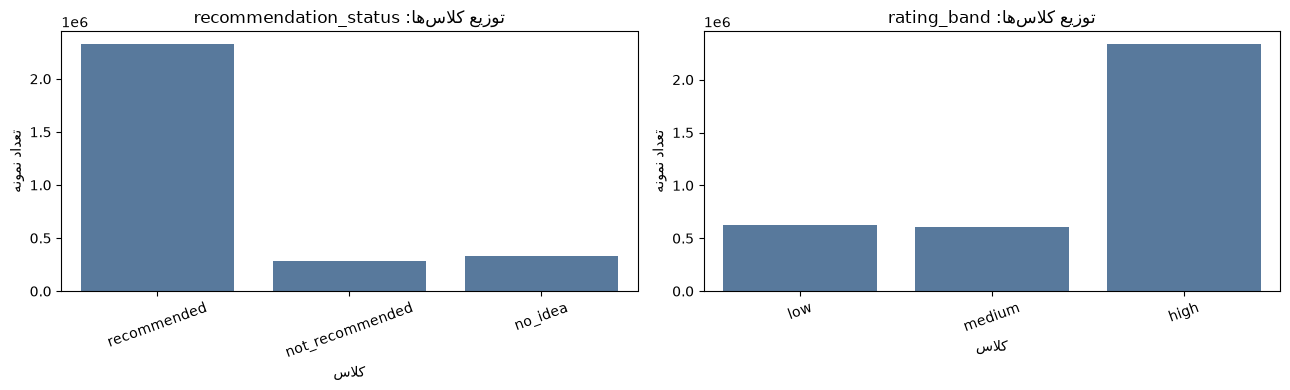

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for axis, target in zip(axes, TARGETS):
    counts = data['train'][target].value_counts(dropna=False)

    print(f'توزیع {target} در train:')
    display(counts.rename('تعداد').to_frame())

    # مقدارهای خالی کلاس نیستند؛ فقط کلاس‌های موجود را بررسی می‌کنیم.
    observed_classes = set(data['train'][target].dropna().unique())
    expected_classes = set(TARGETS[target])
    unexpected = observed_classes - expected_classes

    if unexpected:
        warnings.warn(
            f'کلاس‌های پیش‌بینی‌نشده در {target}: {unexpected}'
        )

    sns.countplot(
        data=data['train'],
        x=target,
        order=TARGETS[target],
        ax=axis,
        color='#4C78A8',
    )

    axis.set_title(f'توزیع کلاس‌ها: {target}')
    axis.set_xlabel('کلاس')
    axis.set_ylabel('تعداد نمونه')
    axis.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


<div dir="rtl">

## 3. ساخت و آموزش baselineها

TF-IDF واژه‌ها و عبارت‌های دوواژه‌ای را به ویژگی‌های عددی تبدیل می‌کند. Logistic Regression روی این ویژگی‌ها سریع، کم‌پیچیدگی و baseline مناسبی برای مقایسه با Transformer است. دو مدل مستقل می‌سازیم، چون هر هدف برچسب‌ها و نمونه‌های معتبر خودش را دارد. هیچ ویژگی‌ای از متادیتا وارد مدل نمی‌شود.

In [12]:
def make_model():
    return Pipeline([
        (
            'tfidf',
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_features=300_000,
                sublinear_tf=True,
            ),
        ),
        (
            'logistic_regression',
            LogisticRegression(
                max_iter=300,
                class_weight='balanced',
                random_state=SEED,
            ),
        ),
    ])

models = {}
for target in TARGETS:
    labeled_rows = data['train'][target].notna()
    if data['train'].loc[labeled_rows, target].nunique() < 2:
        raise ValueError(f'{target}: برای آموزش باید حداقل دو کلاس موجود باشد.')

    model = make_model()
    model.fit(
        data['train'].loc[labeled_rows, TEXT_COLUMN],
        data['train'].loc[labeled_rows, target],
    )
    models[target] = model
    print(f'{target}: آموزش روی {labeled_rows.sum():,} نمونه برچسب‌دار')

E:\MLprojects\Transformer-Project\.project_env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


recommendation_status: آموزش روی 2,946,365 نمونه برچسب‌دار
rating_band: آموزش روی 3,572,366 نمونه برچسب‌دار


E:\MLprojects\Transformer-Project\.project_env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


<div dir="rtl">

## 4. معیارهای ارزیابی

گزارش روی validation و test با معیارهای تعریف پروژه ساخته می‌شود: Accuracy، Macro Precision/Recall/F1، معیارهای هر کلاس، confusion matrix و Balanced Accuracy. برای rating_band علاوه بر آن، میانگین فاصلهٔ بین دستهٔ واقعی و پیش‌بینی‌شده را می‌سنجیم؛ اشتباه بین low و medium یک واحد و بین low و high دو واحد خطاست.

Test فقط برای گزارش نهایی استفاده می‌شود؛ انتخاب یا تنظیم مدل بر مبنای آن انجام نمی‌دهیم.

In [13]:
def evaluate(model, frame, target):
    labeled_rows = frame[target].notna()
    y_true = frame.loc[labeled_rows, target]
    y_pred = model.predict(frame.loc[labeled_rows, TEXT_COLUMN])
    labels = TARGETS[target]

    scores = {
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_precision': precision_score(
            y_true, y_pred, labels=labels, average='macro', zero_division=0
        ),
        'macro_recall': recall_score(
            y_true, y_pred, labels=labels, average='macro', zero_division=0
        ),
        'macro_f1': f1_score(
            y_true, y_pred, labels=labels, average='macro', zero_division=0
        ),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
    }

    if target == 'rating_band':
        class_order = {label: index for index, label in enumerate(labels)}
        distances = [
            abs(class_order[actual] - class_order[predicted])
            for actual, predicted in zip(y_true, y_pred)
        ]
        scores['ordinal_distance_error'] = float(np.mean(distances))

    return y_true, y_pred, scores

results = {}
for split in ['validation', 'test']:
    for target, model in models.items():
        results[(split, target)] = evaluate(model, data[split], target)

metric_table = pd.DataFrame({
    f'{split} | {target}': result[2]
    for (split, target), result in results.items()
}).T
display(metric_table.style.format('{:.4f}'))

,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy,ordinal_distance_error
validation | recommendation_status,0.8052,0.6452,0.7337,0.6753,0.7337,nan
validation | rating_band,0.6583,0.5688,0.5869,0.5726,0.5869,0.4418
test | recommendation_status,0.8056,0.6461,0.7349,0.6764,0.7349,nan
test | rating_band,0.6591,0.5701,0.5886,0.5741,0.5886,0.4411


<div dir="rtl">

## 5. نمودار مقایسهٔ معیارها

این نمودار تفاوت عملکرد روی validation و test را برای هر هدف نشان می‌دهد. اختلاف زیاد می‌تواند نشانهٔ تغییر توزیع نمونه‌ها یا ناپایداری باشد. چون Logistic Regression با solver داخلی آموزش داده می‌شود، این baseline نمودار loss یا روند epoch ندارد؛ آن نوع منحنی برای fine-tuning Transformer مناسب‌تر است.

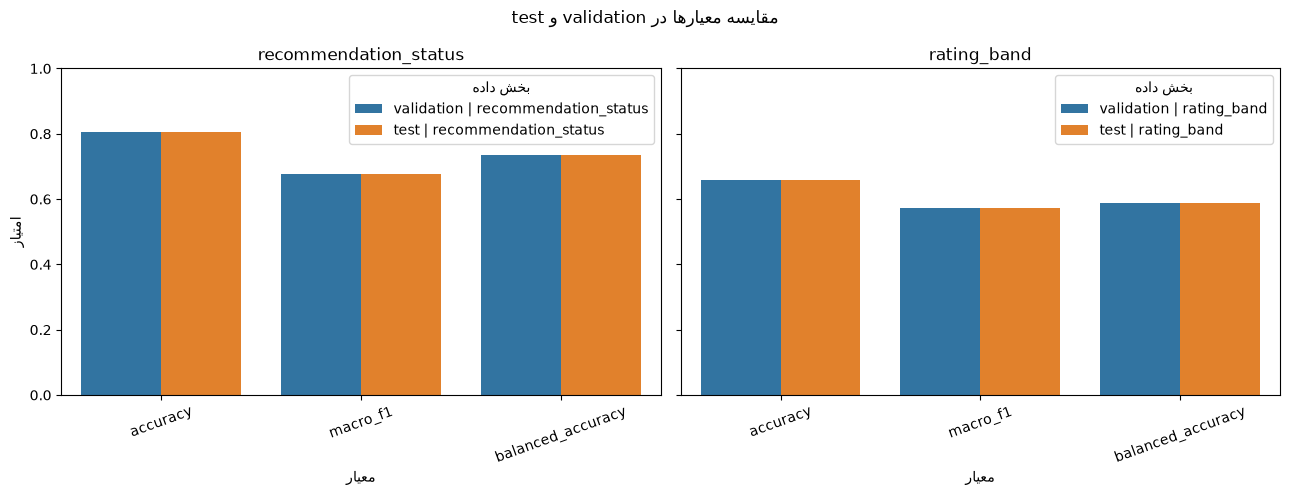

In [14]:
plot_metrics = metric_table.reset_index(names='evaluation')
plot_metrics = plot_metrics.melt(
    id_vars='evaluation', var_name='metric', value_name='score'
)
plot_metrics = plot_metrics[plot_metrics['metric'].isin(
    ['accuracy', 'macro_f1', 'balanced_accuracy']
)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for axis, target in zip(axes, TARGETS):
    subset = plot_metrics[plot_metrics['evaluation'].str.endswith(target)]
    sns.barplot(data=subset, x='metric', y='score', hue='evaluation', ax=axis)
    axis.set_title(target)
    axis.set_xlabel('معیار')
    axis.set_ylabel('امتیاز')
    axis.set_ylim(0, 1)
    axis.tick_params(axis='x', rotation=20)
    axis.legend(title='بخش داده')

plt.suptitle('مقایسه معیارها در validation و test')
plt.tight_layout()
plt.show()

<div dir="rtl">

## 6. گزارش کلاس‌به‌کلاس و confusion matrix

خانه‌های قطر اصلی یعنی پیش‌بینی درست‌اند. نمودار دوم هر سطر را به درصد تبدیل می‌کند تا خطاهای کلاس‌های کم‌نمونه هم دیده شوند.

گزارش test برای recommendation_status:
                 precision    recall  f1-score   support

    recommended      0.962     0.840     0.897    624362
not_recommended      0.632     0.786     0.700     75730
        no_idea      0.344     0.578     0.432     89112

       accuracy                          0.806    789204
      macro avg      0.646     0.735     0.676    789204
   weighted avg      0.861     0.806     0.826    789204

گزارش test برای rating_band:
              precision    recall  f1-score   support

         low      0.525     0.517     0.521    163829
      medium      0.360     0.512     0.423    158843
        high      0.826     0.737     0.779    600676

    accuracy                          0.659    923348
   macro avg      0.570     0.589     0.574    923348
weighted avg      0.692     0.659     0.672    923348



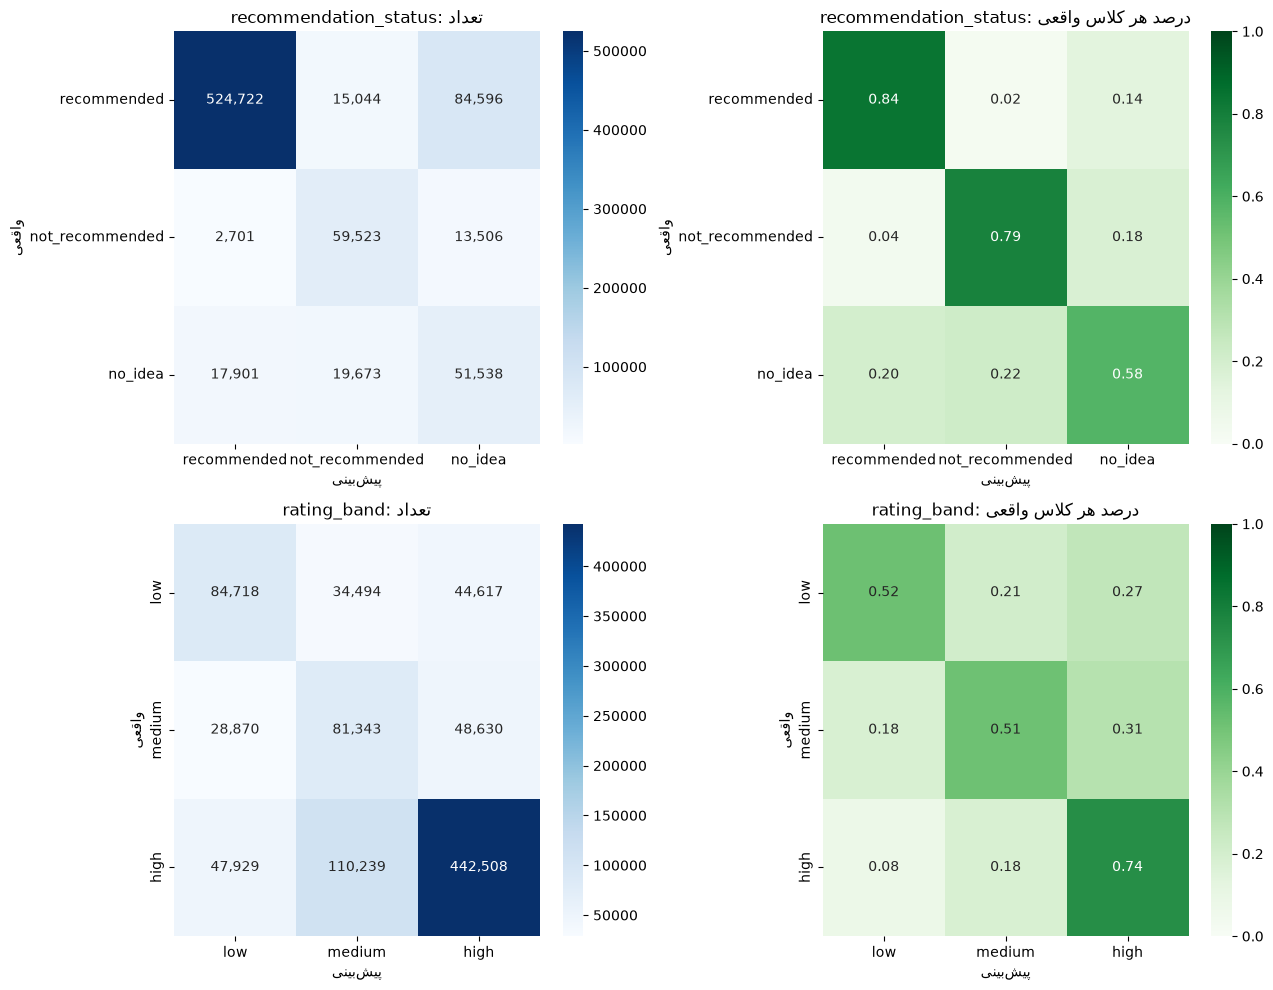

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for row, target in enumerate(TARGETS):
    y_true, y_pred, _ = results[('test', target)]
    labels = TARGETS[target]

    print(f'گزارش test برای {target}:')
    print(classification_report(
        y_true, y_pred, labels=labels, zero_division=0, digits=3
    ))

    counts = confusion_matrix(y_true, y_pred, labels=labels)
    normalized = confusion_matrix(
        y_true, y_pred, labels=labels, normalize='true'
    )
    sns.heatmap(
        counts, annot=True, fmt=',d', cmap='Blues',
        xticklabels=labels, yticklabels=labels, ax=axes[row, 0]
    )
    axes[row, 0].set_title(f'{target}: تعداد')
    axes[row, 0].set_xlabel('پیش‌بینی')
    axes[row, 0].set_ylabel('واقعی')

    sns.heatmap(
        normalized, annot=True, fmt='.2f', cmap='Greens',
        vmin=0, vmax=1, xticklabels=labels, yticklabels=labels,
        ax=axes[row, 1]
    )
    axes[row, 1].set_title(f'{target}: درصد هر کلاس واقعی')
    axes[row, 1].set_xlabel('پیش‌بینی')
    axes[row, 1].set_ylabel('واقعی')

plt.tight_layout()
plt.show()

<div dir="rtl">

## 7. مرور خطاها و واژه‌های شاخص

چند خطای هر هدف را همراه با متن و برچسب واقعی نمایش می‌دهیم تا خطاهایی مثل نفی، متن کوتاه، طعنه و نظر ترکیبی دستی بررسی شوند. ضرایب مثبت Logistic Regression واژه‌هایی را نشان می‌دهند که به امتیاز کلاس کمک کرده‌اند؛ این‌ها هم‌بستگی‌اند و دلیل قطعی پیش‌بینی نیستند.

In [16]:
for target in TARGETS:
    y_true, y_pred, _ = results[('test', target)]
    error_mask = y_true.to_numpy() != y_pred
    errors = data['test'].loc[y_true.index[error_mask], [TEXT_COLUMN, target]].copy()
    errors['prediction'] = y_pred[error_mask]

    print(f'{target}: {len(errors):,} خطا در نمونه test')
    display(errors.head(10))

def most_informative_terms(model, top_n=12):
    vectorizer = model.named_steps['tfidf']
    classifier = model.named_steps['logistic_regression']
    terms = np.asarray(vectorizer.get_feature_names_out())
    rows = []

    for index, label in enumerate(classifier.classes_):
        top_indices = np.argsort(classifier.coef_[index])[-top_n:][::-1]
        rows.append({
            'کلاس': label,
            'واژه‌ها/عبارت‌های شاخص': '، '.join(terms[top_indices]),
        })
    return pd.DataFrame(rows)

for target, model in models.items():
    print(f'واژه‌های شاخص — {target}')
    display(most_informative_terms(model))

recommendation_status: 153,421 خطا در نمونه test


,body,recommendation_status,prediction
24,یکمی استفاده ازش سخته. در کل خوبه,recommended,no_idea
25,اصلا پاک نمیشه خیلی نرمه و پوست رو زخم نمیکنه ...,recommended,not_recommended
33,بسته بندی افتضاح درش باز شده بود,no_idea,not_recommended
35,یکی از دو سر قلمو دانتل کوچک و طرف دیگر باید ب...,recommended,no_idea
36,جالب نبود متاسفانه اون رنگ عسلی درنیومدشخوشم ن...,no_idea,not_recommended
51,بدک نبود اما رنگ زیبا,recommended,no_idea
58,دوماه پیش یک سوم این قیمت خریداری کردم روی جلد...,no_idea,not_recommended
60,این کتاب حتی در کتابفروشی با تخفیف هم، قیمتش ب...,recommended,no_idea
61,وسیله کاربردی هست اما مال من جنسش خیلی نازک بو...,recommended,no_idea
70,بنده قبلا چند بار خرید داشتم این محصول رو ، جن...,no_idea,not_recommended


rating_band: 314,779 خطا در نمونه test


,body,rating_band,prediction
8,کار کردن باهاش راحته. بهداشتیه,high,low
11,این برند لاک پاکن خیلی باکیفیته ولی متاسفانه ب...,medium,low
12,تعداد توپک ها زیاده و هر کدوم حجم خوبی دارن قی...,high,medium
17,در کل خوبه,medium,high
18,تمام پلاستیکی بودن و جنس پلاستیک باعث میشه الک...,low,medium
22,رنگ مداد قهوه ای تیره هست ولی مداد حالت چرب دا...,low,medium
23,نسبت به قیمت خیلی خوبه هنوز استفاده نکردم اما ...,high,medium
25,اصلا پاک نمیشه خیلی نرمه و پوست رو زخم نمیکنه ...,high,low
29,عالی بود کیفیتش،رنگش،سفتیش،نرم بودن شونه من بر...,low,high
32,خوبه نسبت به قیمت,high,medium


واژه‌های شاخص — recommendation_status


,کلاس,واژه‌ها/عبارت‌های شاخص
0,no_idea,شک دارم، نداره همونی، ویژه تهیه، مطمئن نیستم، ...
1,not_recommended,بدترین، افتضاحه، متاسفم، آشغاله، فاجعه، اصلا، ...
2,recommended,بد نیست، عالی فقط، عالین، بد نبود، اذیت نمیکنه...


واژه‌های شاخص — rating_band


,کلاس,واژه‌ها/عبارت‌های شاخص
0,high,نازک نیست، خراب نمیشه، بد نبود، آموزشگاه، بد ن...
1,low,بدترین، آشغاله، متاسفم، افتضاحه، اشغاله، فاجعه...
2,medium,کاملا معمولیه، کاملا معمولی، 20 به، معولی، معم...


<div dir="rtl">

## جمع‌بندی و ملاحظات

- این دو مدل baseline برای هر دو هدف الزامی‌اند و با Transformer روی همان splitها مقایسه می‌شوند.
- تنها feature مدل متن body است؛ نرخ خام، وضعیت توصیه، شناسه محصول و سایر metadata وارد مدل نشده‌اند.
- rating_band از پیش در preprocess با آستانه‌های پروژه ساخته شده: low از ۰ تا کمتر از ۲٫۵، medium از ۲٫۵ تا کمتر از ۴، و high از ۴ تا ۵.
- واژگان TF-IDF و ضرایب هر مدل فقط از train آموخته می‌شوند. splitهای validation و test فقط ارزیابی می‌شوند.
- ورودی‌ها از قبل توسط preprocess نرمال شده‌اند؛ در این فایل دوباره نرمال‌سازی انجام نمی‌دهیم.
- نمونه‌گیری فعلی برای اجرای عملی است. برای نتایج کامل LIMITS را None کنید و حجم نمونه را در گزارش ثبت کنید.
- خروجی معیارها، نمودار توزیع کلاس‌ها، نمودار مقایسهٔ معیارها و confusion matrixها ابزار تحلیل baseline هستند؛ این نوت‌بوک pseudo-labeling را اجرا نمی‌کند.